# 📘 Explained copy — 09 Liquidity reserve and stress test (extra module)

Study copy of `notebooks/09_liquidity_stress.ipynb`. Original cells unchanged (with outputs); above each is an
**Explanation**: *what it does · why this method · input → output · how to read the output vs alternatives*.

**Story for the report.** The brief lists liquidity reserves as a use of the ₹1,000 cr but has no module, so we size it
from `nova_liquidity.csv`. We recover the column identities (gap = outflows − inflows; buffer = cash + 80% securities),
read units as ₹ lakh (deposits ₹506 cr, buffer ₹114 cr), and find the **structural problem**: a ₹4.9 cr/day net outflow
funded almost exactly by wholesale funding (₹5.0 cr/day). Forecasting tomorrow's gap (time split 70/30): Ridge ≈ 20-day
average ≫ naive, but R² ≈ 0 → forecasting cannot replace a reserve. **LCR-style historical simulation** over every
30-day window at 99%: policy scenario B (wholesale freeze + 10% deposit run) needs ₹286 cr → shortfall ₹172 cr →
**hold a ₹175 cr reserve** (+ ₹84 cr contingency for the severe case).

> ### 📘 Explanation — cell 0
> **Why this notebook exists.** The corrected brief has liquidity reserves as an allocation destination but no module;
> the data file exists, so we answer: *how much of ₹1,000 cr to keep as a liquidity reserve to survive a funding stress?*
> Chain: daily flows → ML early-warning forecast → stressed 30-day outflow → compare with buffer → reserve.

# 09. Liquidity reserve and stress test (extra module)

**Why this notebook exists.** The corrected brief lists **liquidity reserves** as a destination for the ₹1,000 crore
but has no liquidity module. `nova_liquidity.csv` is provided, so we use it to answer one Board question:

**How much of the ₹1,000 crore should be kept as a liquidity reserve so NovaFin survives a funding stress?**

**Chain.** Daily cash flows → ML forecast of tomorrow's liquidity gap (early warning) → stressed 30-day cumulative
outflow (funding freeze, deposit run) → compare with the existing buffer → **reserve to hold** (feeds notebook 10).

> ### 📘 Explanation — cell 1
> **What it does.** Loads helpers and sets output folders (Extra_Liquidity_Reserve).

In [1]:
import sys; sys.path.insert(0, '../src')   # make the shared helper module importable
from novafin import *                       # shared assumptions, loaders, metrics, plot style
RES, FIG = use_module('09')                 # this module's output folders (results/ and figures/)

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Extra_Liquidity_Reserve/ and figures/Extra_Liquidity_Reserve/


> ### 📘 Explanation — cell 2
> **What it does.** Imports Ridge and HistGB regressors (forecasters), scaler, pipeline.

In [2]:
from sklearn.linear_model import Ridge                                  # linear forecaster
from sklearn.ensemble import HistGradientBoostingRegressor              # tree forecaster
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

> ### 📘 Explanation — cell 3
> **What it does.** Loads daily liquidity data in time order.
>
> **Output.** (1,216, 13), 2022-01-03 → 2026-08-31: deposits, disbursements, repayments, wholesale funding, securities,
> cash, expected inflows/outflows, rate, market stress, gap, buffer.

In [3]:
liq = load('liquidity', parse_dates=['Date']).sort_values('Date').reset_index(drop=True)   # daily, time order
print(liq.shape, '|', liq.Date.min().date(), 'to', liq.Date.max().date())
liq.head(3)

(1216, 13) | 2022-01-03 to 2026-08-31


,Date,Deposits,Loan_Disbursements,Loan_Repayments,Wholesale_Funding,Securities_Holdings,Cash,Expected_Inflows,Expected_Outflows,Interest_Rate,Market_Stress,Liquidity_Gap,Liquidity_Buffer
0,2022-01-03,49994.80,1746.24,1279.89,550.09,7999.74,4999.54,2445.30,2948.13,6.04,0.047,502.84,11399.33
1,2022-01-04,50049.38,1482.28,1247.09,529.10,7998.61,4999.54,2295.56,2642.25,7.95,-0.584,346.68,11398.43
2,2022-01-05,50085.97,2153.28,1277.38,299.83,7998.91,5000.08,2495.94,3497.37,6.17,0.862,1001.43,11399.21


> ### 📘 Explanation — cell 4
> **Section header** – what do the columns mean?

## 1. Audit: what do the columns mean?

> ### 📘 Explanation — cell 5
> **What it does.** Missing/duplicate check; tests two identities: Gap = Outflows − Inflows, Buffer = Cash + 0.8 × Securities.
>
> **Output.** 0 missing; max differences 0.01 and 0.012 (rounding) → **both identities hold exactly**.
>
> **Why.** Knowing the exact definitions means stress tests can be built from the components (outflows, inflows, funding)
> rather than treating the gap as a black box. The 20% haircut mirrors regulatory HQLA treatment.

In [4]:
print('Missing values:', int(liq.isna().sum().sum()), '| duplicate dates:', int(liq.Date.duplicated().sum()))
gap_check = np.abs(liq.Liquidity_Gap - (liq.Expected_Outflows - liq.Expected_Inflows)).max()
buf_check = np.abs(liq.Liquidity_Buffer - (liq.Cash + 0.8 * liq.Securities_Holdings)).max()
print('Liquidity_Gap = Outflows - Inflows ? max difference:', round(gap_check, 3))
print('Liquidity_Buffer = Cash + 80% of Securities ? max difference:', round(buf_check, 3))

Missing values: 0 | duplicate dates: 0
Liquidity_Gap = Outflows - Inflows ? max difference: 0.01
Liquidity_Buffer = Cash + 80% of Securities ? max difference: 0.012


> ### 📘 Explanation — cell 6
> **Definitions + units.** Positive gap = net cash leaving. Units read as ₹ lakh (README): deposits ≈ ₹506 cr, buffer ≈ ₹114 cr — consistent with the ₹640 cr loan book and the ₹1,000 cr budget (as crore it would be a ₹50,000 cr bank).

**Definitions recovered exactly from the data.**
- `Liquidity_Gap` = expected outflows − expected inflows, per day. **Positive = net cash leaving.**
- `Liquidity_Buffer` = cash + 80% of securities (a 20% haircut on securities, as in regulatory liquidity rules).

**Units.** The README says money is in **₹ lakh**. Read that way, NovaFin has about ₹506 crore of deposits and a
₹114 crore buffer, the same scale as the ₹640 crore loan book and the ₹1,000 crore budget. (Read as crore, this would
be a ₹50,000 crore bank for which the ₹1,000 crore question hardly matters.) We use **lakh** and convert to crore.

> ### 📘 Explanation — cell 7
> **What it does.** Mean/std/min/max of the key columns in ₹ crore (lakh ÷ 100).
>
> **Output.** Deposits ₹505.6 cr, wholesale ₹5.0 cr/day, inflows ₹25.1 cr, outflows ₹30.0 cr, **gap ₹4.9 cr/day** (−9.3 to +20.8),
> **buffer ₹113.9 cr** (almost constant).

In [5]:
TO_CR = 1e5 / CRORE                                     # ₹ lakh -> ₹ crore (divide by 100)
summary = (liq[['Deposits', 'Wholesale_Funding', 'Expected_Inflows', 'Expected_Outflows', 'Liquidity_Gap', 'Liquidity_Buffer']]
           .agg(['mean', 'std', 'min', 'max']).T * TO_CR)
summary.round(2).rename(columns=lambda c: f'{c} (₹ cr)')

,mean (₹ cr),std (₹ cr),min (₹ cr),max (₹ cr)
Deposits,505.58,9.22,486.46,523.18
Wholesale_Funding,5.00,1.19,1.27,8.67
Expected_Inflows,25.09,2.87,15.26,34.09
Expected_Outflows,29.99,3.35,17.55,41.76
Liquidity_Gap,4.90,4.48,-9.31,20.75
Liquidity_Buffer,113.85,0.11,113.66,114.05


> ### 📘 Explanation — cell 8
> **What it does.** (1) 20-day averages of gap vs wholesale funding; (2) gap histogram; (3) correlation of drivers with the
> gap. Saves `liquidity_eda.png`.
>
> **Output.** Net outflow on **86.8%** of days; avg gap ₹4.9 cr/day vs wholesale ₹5.0 cr/day.
>
> **How to read.** The two lines in panel 1 overlap → wholesale funding plugs the daily gap. Disbursements (out) and
> repayments (in) drive the gap; market stress and rates show no link here.

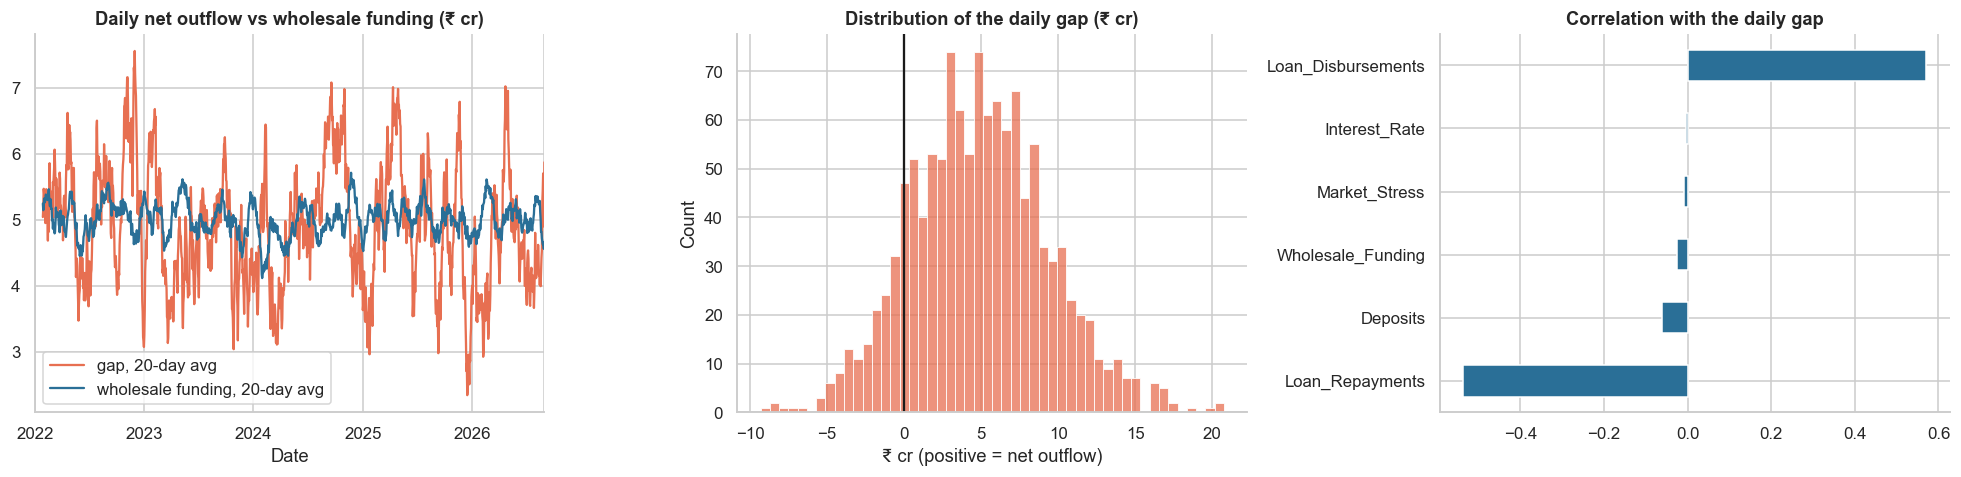

Days with net outflow: 0.868 | average gap ₹ 4.9 cr/day | average wholesale funding ₹ 5.0 cr/day


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
(liq.set_index('Date').Liquidity_Gap * TO_CR).rolling(20).mean().plot(ax=ax[0], c='#e76f51', label='gap, 20-day avg')
(liq.set_index('Date').Wholesale_Funding * TO_CR).rolling(20).mean().plot(ax=ax[0], c='#2a6f97', label='wholesale funding, 20-day avg')
ax[0].set(title='Daily net outflow vs wholesale funding (₹ cr)'); ax[0].legend()
sns.histplot(liq.Liquidity_Gap * TO_CR, bins=50, ax=ax[1], color='#e76f51'); ax[1].axvline(0, c='k')
ax[1].set(title='Distribution of the daily gap (₹ cr)', xlabel='₹ cr (positive = net outflow)')
c = liq[['Loan_Disbursements', 'Loan_Repayments', 'Wholesale_Funding', 'Interest_Rate', 'Market_Stress', 'Deposits', 'Liquidity_Gap']].corr()['Liquidity_Gap'].drop('Liquidity_Gap')
c.sort_values().plot(kind='barh', ax=ax[2], color='#2a6f97'); ax[2].set_title('Correlation with the daily gap')
plt.tight_layout(); savefig('liquidity_eda'); plt.show()
print('Days with net outflow:', round((liq.Liquidity_Gap > 0).mean(), 3), '| average gap ₹', round(liq.Liquidity_Gap.mean() * TO_CR, 2), 'cr/day',
      '| average wholesale funding ₹', round(liq.Wholesale_Funding.mean() * TO_CR, 2), 'cr/day')

> ### 📘 Explanation — cell 9
> **Reading.** The bank relies on wholesale funding — the first source to disappear in a crisis. That is the risk the reserve must cover.

**Reading.** On 86% of days more cash leaves than arrives, about ₹4.9 crore a day net. That gap is funded almost
exactly by **wholesale funding** (≈ ₹5 crore a day), money borrowed from other institutions, which is the first
source to disappear in a crisis. The gap is driven by loan disbursements (out) and repayments (in). Market stress
and interest rates show no link to it in this data.

> ### 📘 Explanation — cell 10
> **Forecast design.** Target = tomorrow's gap; features known today (lags, rolling means, today's flows, day-of-week, month-end); **time split 70/30**, never shuffled; benchmarks: naive (tomorrow = today) and 20-day average.

## 2. ML forecast of tomorrow's gap (early-warning tool)
Target: tomorrow's gap. Features: only what is known today: recent gaps (lags and rolling means), today's flows,
day of week, month-end flag. **Time split**: first 70% of days train, last 30% test, never shuffled.
Benchmarks: **naive** (tomorrow = today) and **20-day average**.

> ### 📘 Explanation — cell 11
> **What it does.** `Target = gap.shift(−1)`; lags 0/1/4, rolling 5- and 20-day means, flows, DoW, month-end flag; drops
> incomplete rows; first 70% train, last 30% test.
>
> **Output.** Train 2022-01-28 → 2025-04-14; test 2025-04-15 → 2026-08-28.
>
> **Why lags/rolling means.** Standard time-series features: they capture persistence and level without using the future.

In [7]:
d = liq.copy()
d['Target'] = d.Liquidity_Gap.shift(-1)                                     # tomorrow's gap (what we forecast)
for k in (1, 2, 5):
    d[f'Gap_lag{k - 1}'] = d.Liquidity_Gap.shift(k - 1)                    # today's gap and earlier ones
d['Gap_mean5'] = d.Liquidity_Gap.rolling(5).mean()                         # last week's average
d['Gap_mean20'] = d.Liquidity_Gap.rolling(20).mean()                       # last month's average
d['DoW'] = d.Date.dt.dayofweek                                              # Monday = 0
d['Month_End'] = d.Date.dt.is_month_end.astype(int)                        # salary / EMI days
FEATURES = ['Gap_lag0', 'Gap_lag1', 'Gap_lag4', 'Gap_mean5', 'Gap_mean20', 'Loan_Disbursements', 'Loan_Repayments',
            'Wholesale_Funding', 'Deposits', 'Interest_Rate', 'Market_Stress', 'DoW', 'Month_End']
d = d.dropna(subset=FEATURES + ['Target']).reset_index(drop=True)
cut = int(len(d) * 0.7)
tr, te = d.iloc[:cut], d.iloc[cut:]
print('train', tr.Date.min().date(), '-', tr.Date.max().date(), '| test', te.Date.min().date(), '-', te.Date.max().date())

train 2022-01-28 - 2025-04-14 | test 2025-04-15 - 2026-08-28


> ### 📘 Explanation — cell 12
> **What it does.** Fits Ridge (α = 10) and GB on train; compares with naive and 20-day average on test (RMSE, MAE, R²);
> chooses the simplest method within 2% of the best RMSE.
>
> **Output (RMSE ₹ cr).** Ridge **4.60** · 20-day avg **4.68 (chosen)** · GB 4.75 · naive **6.50**. R² ≈ 0 for all useful models (naive −1.05).
>
> **How to read.** The daily gap is noise around a stable mean: averaging beats "tomorrow = today" by ~₹1.8 cr, and ML adds
> almost nothing over a 20-day average → simplest wins. A forecast is useful for monitoring, not for sizing protection.

In [8]:
fc = {'Naive (tomorrow = today)': te.Gap_lag0.values, '20-day average': te.Gap_mean20.values}
models = {'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
          'Gradient boosting': HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED)}
for n, m in models.items():
    fc[n] = m.fit(tr[FEATURES], tr.Target).predict(te[FEATURES])           # fit on the first 70% only
y = te.Target.values
perf = pd.DataFrame({n: {'RMSE ₹ cr': np.sqrt(((p - y) ** 2).mean()) * TO_CR, 'MAE ₹ cr': np.abs(p - y).mean() * TO_CR,
                         'R²': 1 - ((p - y) ** 2).sum() / ((y - y.mean()) ** 2).sum()} for n, p in fc.items()}).T
order = ['20-day average', 'Ridge', 'Gradient boosting']                  # simplest useful model first
best = perf.loc[order, 'RMSE ₹ cr'].idxmin()
chosen = next(m for m in order if perf.loc[m, 'RMSE ₹ cr'] <= perf.loc[best, 'RMSE ₹ cr'] * 1.02)
cmp = compare_models(perf, 'RMSE ₹ cr', higher_is_better=False, chosen=chosen, baseline='Naive (tomorrow = today)', extra=['MAE ₹ cr', 'R²'])
cmp.rename(columns={'Gain vs baseline': '₹ cr RMSE saved vs naive'}).round(3)

,Rank,RMSE ₹ cr,MAE ₹ cr,R²,₹ cr RMSE saved vs naive,Gap to best,Chosen
Ridge,1,4.596,3.622,-0.022,1.907,-0.000,
20-day average,2,4.679,3.703,-0.059,1.825,0.082,✔
Gradient boosting,3,4.752,3.765,-0.093,1.751,0.156,
Naive (tomorrow = today),4,6.503,5.034,-1.047,-0.000,1.907,


> ### 📘 Explanation — cell 13
> **Benefit of the choice.** Models help mainly by *not* chasing yesterday's number; real protection must come from the reserve.

**Benefit of the choice.** The comparison shows how much forecast error each method removes versus "tomorrow = today".
Daily gaps are mostly unpredictable noise around a stable average, so a model mainly helps by **not** chasing
yesterday's number. The real protection therefore has to come from the **reserve**, sized next, not from forecasting.

> ### 📘 Explanation — cell 14
> **Stress design (LCR logic).** Buffer must cover **30 days of net outflows under stress**. Scenarios: Normal (wholesale
> rolls), A freeze, B freeze + 10% deposit run + inflows −5% (**policy**), C freeze + 20% run + inflows −10%.
> Run-off rates follow the LCR idea that 5–10% of stable retail deposits can leave in 30 days.
> **Method = historical simulation:** every overlapping 30-day window in history (~1,187), apply scenario, take the 99th
> percentile — same idea as historical VaR, keeps real day-to-day patterns.

## 3. Stress test: how much reserve is needed to survive 30 days?
We follow the logic of the regulatory **Liquidity Coverage Ratio (LCR)**: the buffer must cover **30 days of
net outflows under stress**. Scenarios:

| Scenario | What happens for 30 days |
|---|---|
| Normal | Wholesale funding keeps rolling (it covers the gap). |
| A. Funding freeze | Wholesale funding stops: the buffer must cover the full gap. |
| B. Freeze + deposit run (LCR-style) | Freeze, plus **10% of deposits** withdrawn over the month and inflows −5% (borrowers delay). |
| C. Severe | Freeze, **20% of deposits** withdrawn, inflows −10%. |

The run-off rates follow the logic of the regulatory LCR, which assumes that roughly 5–10% of stable retail deposits
(and much more of less stable funding) can leave during 30 days of stress.

**Method: historical simulation** (the same idea as historical VaR in Session 12). We take **every 30-day window**
in the 2022–2026 history (about 1,190 overlapping windows of real days), apply each scenario to it, and add up the
daily need. The 99th percentile across windows is the "bad but plausible" 30-day need.

> ### 📘 Explanation — cell 15
> **What it does.** Builds a window-index matrix (start × 30 days); for each scenario computes daily net need =
> outflows + run-off × deposits/30 − inflow multiplier × inflows − (wholesale if on); peak cumulative need per window;
> 99th percentile; coverage ratio (buffer/need99), survival days (buffer / average daily need), shortfall.
>
> **Output.**
> | Scenario | 30-day need 99% | Coverage | Survival | Shortfall |
> |---|---|---|---|---|
> | Normal | ₹56.6 cr | 2.01 | ∞ | 0 |
> | A freeze | ₹199.2 cr | 0.57 | 23 days | ₹85.4 cr |
> | **B freeze + run** | **₹285.8 cr** | **0.40** | **15 days** | **₹172.0 cr** |
> | C severe | ₹372.4 cr | 0.31 | 11 days | ₹258.6 cr |
>
> **How to read.** Coverage < 1 = buffer insufficient (like LCR < 100%). Under the policy scenario the current buffer lasts only ~15 days.

In [9]:
H = 30                                                                          # stress horizon in days (as in the LCR)
starts = np.arange(len(liq) - H + 1)                                            # every possible start day in history
idx = starts[:, None] + np.arange(H)                                            # day indices of each 30-day window
out_, in_, wf = liq.Expected_Outflows.values[idx], liq.Expected_Inflows.values[idx], liq.Wholesale_Funding.values[idx]

SCEN = {'Normal': (0.00, 1.00, True), 'A. Funding freeze': (0.00, 1.00, False),    # (deposit run-off, inflow multiplier, wholesale on?)
        'B. Freeze + deposit run': (0.10, 0.95, False), 'C. Severe': (0.20, 0.90, False)}
buffer_now = liq.Liquidity_Buffer.iloc[-1]                                      # latest buffer (₹ lakh)
deposits_now = liq.Deposits.iloc[-1]                                            # latest deposits (₹ lakh)
rows = {}
for name, (runoff, i_mult, wholesale_on) in SCEN.items():
    net = out_ + runoff * deposits_now / H - i_mult * in_ - (wf if wholesale_on else 0)   # daily need not covered by funding
    cum = net.sum(axis=1)                                                       # 30-day cumulative need
    worst_running = np.maximum.accumulate(net.cumsum(axis=1), axis=1)[:, -1]   # peak need along the path
    need99 = np.quantile(worst_running, 0.99)
    daily_mean = net.mean()
    rows[name] = {'avg daily need ₹ cr': daily_mean * TO_CR, '30-day need, mean ₹ cr': cum.mean() * TO_CR,
                  '30-day need, 99% ₹ cr': need99 * TO_CR, 'buffer ₹ cr': buffer_now * TO_CR,
                  'coverage ratio (buffer / need99)': buffer_now / need99 if need99 > 0 else np.inf,
                  'survival days': buffer_now / daily_mean if daily_mean > 0 else np.inf,
                  'shortfall ₹ cr': max(0.0, need99 - buffer_now) * TO_CR}
stress = pd.DataFrame(rows).T
stress.round(2)

,avg daily need ₹ cr,"30-day need, mean ₹ cr","30-day need, 99% ₹ cr",buffer ₹ cr,coverage ratio (buffer / need99),survival days,shortfall ₹ cr
Normal,-0.12,-3.53,56.55,113.82,2.01,inf,0.00
A. Funding freeze,4.89,146.63,199.20,113.82,0.57,23.29,85.38
B. Freeze + deposit run,7.81,234.24,285.81,113.82,0.40,14.58,171.99
C. Severe,10.73,321.85,372.40,113.82,0.31,10.61,258.59


> ### 📘 Explanation — cell 16
> **What it does.** 99th-percentile cumulative need path over 30 days for each scenario vs the buffer line (`liquidity_stress.png`). The day each line crosses the buffer = survival time.

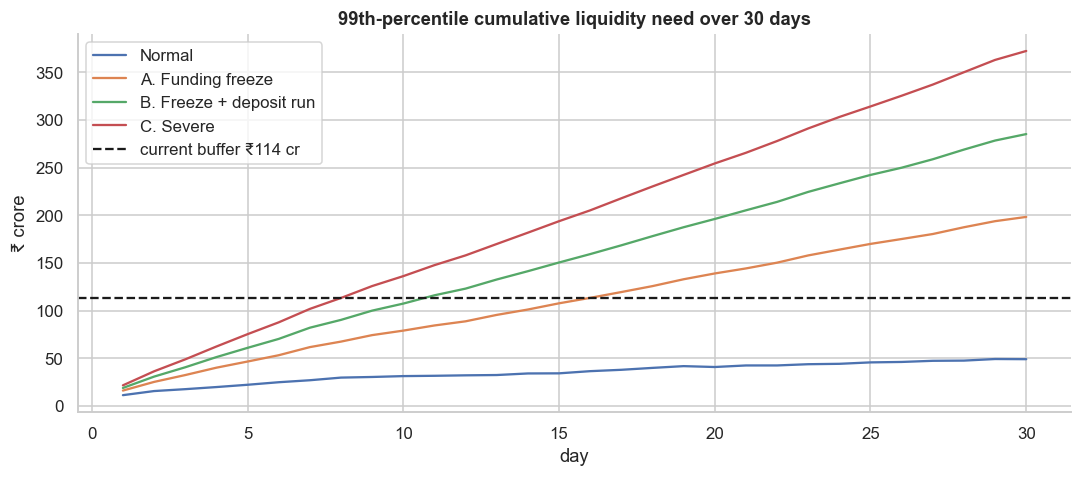

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, (runoff, i_mult, wholesale_on) in SCEN.items():
    net = out_ + runoff * deposits_now / H - i_mult * in_ - (wf if wholesale_on else 0)
    path = np.quantile(net.cumsum(axis=1), 0.99, axis=0) * TO_CR                # 99th percentile cumulative need per day
    ax.plot(range(1, H + 1), path, label=name)
ax.axhline(buffer_now * TO_CR, c='k', ls='--', label=f'current buffer ₹{buffer_now * TO_CR:.0f} cr')
ax.set(title='99th-percentile cumulative liquidity need over 30 days', xlabel='day', ylabel='₹ crore'); ax.legend()
plt.tight_layout(); savefig('liquidity_stress'); plt.show()

> ### 📘 Explanation — cell 17
> **Reading.** Normal: buffer barely touched. Freeze: buffer runs out in weeks; with a deposit run, much faster. Shortfall = extra HQLA (cash, G-secs) to hold.

**Reading the stress test.** In normal times wholesale funding covers the gap and the buffer is barely touched. If
wholesale funding freezes, the buffer runs out in a few weeks. Add a deposit run and it runs out much faster.
The **shortfall** under the stress scenario we adopt is the extra high-quality liquid assets (cash, government bonds)
NovaFin should hold.

> ### 📘 Explanation — cell 18
> **Policy (assumption).** Survive scenario B for 30 days at 99% without selling loans or emergency funding; C reported as a severe check. Reserve held in cash/G-secs yielding ~6.5% (risk-free minus a liquidity discount).

## 4. Reserve sizing and policy
**Policy adopted (stated assumption):** NovaFin must survive **scenario B (freeze + 10% deposit run-off) for 30 days at
99% confidence** without selling loans or raising emergency funding. Scenario C is reported as a severe check.
The reserve is held in cash and government securities (earning roughly the risk-free 7% minus a liquidity
discount, assumed 6.5%).

> ### 📘 Explanation — cell 19
> **What it does.** Reserve = scenario-B shortfall rounded up to the next ₹5 cr; extra needed for scenario C.
>
> **Output.** **Reserve ₹175 crore**; extra ₹84 cr for the severe case.
>
> **Why round up.** Prudence and a clean number for the Board; the sensitivity list shows A ₹85 cr, B ₹172 cr, C ₹259 cr.

In [11]:
POLICY = 'B. Freeze + deposit run'
reserve_cr = float(np.ceil(stress.loc[POLICY, 'shortfall ₹ cr'] / 5) * 5)       # round up to the next ₹5 crore
severe_gap_cr = float(stress.loc['C. Severe', 'shortfall ₹ cr'])
print(f'Reserve needed for {POLICY}: ₹{reserve_cr:.0f} crore')
print(f'Extra needed to also cover the severe scenario: ₹{max(0, severe_gap_cr - reserve_cr):.0f} crore')
sens = pd.Series({k: v for k, v in stress['shortfall ₹ cr'].items()}, name='reserve needed ₹ cr')
sens.round(1).to_frame()

Reserve needed for B. Freeze + deposit run: ₹175 crore
Extra needed to also cover the severe scenario: ₹84 crore


,reserve needed ₹ cr
Normal,0.0
A. Funding freeze,85.4
B. Freeze + deposit run,172.0
C. Severe,258.6


> ### 📘 Explanation — cell 20
> **Monitoring triggers.** Forecast gap > 95th percentile → pre-arrange funding; scenario-B coverage < 110% → stop new wholesale-funded lending; wholesale funding 30% below its 20-day average for 3 days → activate contingency funding plan. (This is where the forecaster earns its place.)

**Monitoring triggers (control framework).**
- Forecast gap for tomorrow above the 95th percentile of history → treasury pre-arranges funding.
- Coverage ratio under scenario B below 110% → stop new wholesale-funded lending.
- Wholesale funding falls 30% below its 20-day average for 3 days → activate the contingency funding plan.

> ### 📘 Explanation — cell 21
> **What it does.** Saves `liquidity.json` (units, horizon, confidence, policy, reserve yield, method, forecast table, chosen forecaster, stress table, current buffer, reserve ₹175 cr, severe extra) for notebook 10.

In [12]:
res = {'module': 'liquidity',
       'assumptions': {'units': 'INR lakh (README), converted to crore', 'horizon_days': H, 'confidence': 0.99,
                       'policy_scenario': POLICY, 'reserve_yield': 0.065, 'method': f'historical simulation, {len(starts)} windows of {H} days'},
       'forecast': perf.round(4).to_dict(orient='index'), 'chosen_forecaster': chosen,
       'stress': stress.replace(np.inf, None).round(3).to_dict(orient='index'),
       'buffer_now_cr': buffer_now * TO_CR, 'reserve_cr': reserve_cr, 'severe_extra_cr': max(0, severe_gap_cr - reserve_cr)}
save_result('liquidity', res)

saved results/Extra_Liquidity_Reserve/liquidity.json


> ### 📘 Explanation — cell 22
> **Headline results & limitations** – identities, wholesale dependence, forecasts ≈ noise, stress table, ₹175 cr reserve. Limitations: not in the brief, units inferred, history-bound simulation, judgemental run-off rates, haircut could be worse in fire sales.

## Headline results
- **Data identities.** Gap = outflows − inflows; buffer = cash + 80% of securities. Read in ₹ lakh (README): deposits
  ₹506 cr, buffer ₹114 cr.
- **The structural issue.** Cash flows out on 87% of days (₹4.9 cr a day on average), and this is funded almost exactly by
  **wholesale funding** (₹5.0 cr a day), the first source to vanish in a crisis.
- **Forecasting (time split, last 30% of days).** Ridge RMSE ₹4.60 cr, 20-day average ₹4.68 cr (chosen: simplest within
  2%), gradient boosting ₹4.75 cr, naive "tomorrow = today" ₹6.50 cr. R² ≈ 0: the daily gap is noise around a stable
  average. Forecasting helps monitoring but **cannot replace a reserve**.
- **Stress (30 days, 99%, historical simulation over every 30-day window).**

| Scenario | 30-day need | Shortfall vs buffer | Survival without reserve |
|---|---|---|---|
| A. Wholesale funding freeze | ₹199 cr | ₹85 cr | 23 days |
| **B. Freeze + 10% deposit run (policy)** | ₹286 cr | **₹172 cr** | 15 days |
| C. Severe: freeze + 20% run | ₹372 cr | ₹259 cr | 11 days |

- **Decision for notebook 10:** hold a **₹175 crore liquidity reserve** (cash and government securities), plus a
  contingency plan for a further ₹84 cr in the severe case, with the monitoring triggers listed above.

## Risks and limitations
- Not part of the corrected brief; units (lakh) are inferred from the README and scale.
- Historical simulation reuses history: a crisis worse than anything in 2022-2026 is only covered by the scenario multipliers.
- Behavioural assumptions (10% / 20% deposit run-off, lower inflows) are judgement, not estimated; the sensitivity table shows
  the effect of the severe case.
- The buffer's 20% haircut on securities is taken from the data; fire-sale prices in a crisis could be worse.